## 1. Revisão humana direcionada — reaproveitamento do histórico em `analysis/auditoria_duplicatas`

**Complemento independente das seções 1–8.** Nenhuma célula anterior foi alterada. Execute **apenas as células de código da seção 9, em ordem**, usando os arquivos **já produzidos** em `training/analysis/auditoria_duplicatas/`. Não executa novamente SHA-256, dHash/pHash, treinamento, construção dos crops ou separação de partições.

As novas etapas:
1. Lê o histórico e confere os IDs dos **1.224 pares** já encontrados, sem modificá-los.
2. Permite registrar os **18 pares prioritários** efetivamente inspecionados (após informar responsável/data e confirmar explicitamente).
3. Agrupa as relações de similaridade **sem inferir identidade**, seleciona até **12 pares adicionais** envolvendo o teste e gera pranchas usando os crops locais.
4. Importa **somente decisões humanas preenchidas**, preservando registros anteriores, e escreve **um relatório complementar** com a cobertura real e as pendências.

A planilha principal `revisao_pares_entre_particoes.csv` é atualizada **somente** por decisões confirmadas e com cópia de segurança. Os relatórios originais de auditoria ficam intactos; o novo `relatorio_triagem_humana.md` é o documento atualizado para anexar ao parecer. **Não apague a pasta `analysis`.**

In [2]:
# 1.0 — Carregar SOMENTE os resultados históricos já existentes.
from pathlib import Path
from collections import defaultdict
from datetime import date, datetime, timezone
from IPython.display import display
import hashlib
import json
import os
import shutil
import tempfile

import pandas as pd
from PIL import Image, ImageDraw, ImageOps

# Defina uma raiz manual somente se estiver executando fora da pasta do projeto.
RH_PROJETO_MANUAL = None  # Ex.: Path('/home/usuario/synthetic-face-detection')


def rh_localizar_projeto() -> Path:
    if RH_PROJETO_MANUAL is not None:
        caminhos = [Path(RH_PROJETO_MANUAL).expanduser().resolve()]
    else:
        atual = Path.cwd().resolve()
        caminhos = [atual, *atual.parents]
    for raiz in caminhos:
        destino = raiz / 'training' / 'analysis' / 'auditoria_duplicatas'
        if (destino / 'revisao_pares_entre_particoes.csv').is_file():
            return raiz
    raise FileNotFoundError(
        'Histórico não encontrado: training/analysis/auditoria_duplicatas/'
        'revisao_pares_entre_particoes.csv. Não apague nem regenere o histórico; '
        'confira RH_PROJETO_MANUAL e a pasta atual do Jupyter.'
    )

RH_PROJETO = rh_localizar_projeto()
RH_HIST = RH_PROJETO / 'training' / 'analysis' / 'auditoria_duplicatas'
RH_PRANCHAS = RH_HIST / 'pranchas'
RH_PRANCHAS.mkdir(parents=True, exist_ok=True)
RH_PRINCIPAL = RH_HIST / 'revisao_pares_entre_particoes.csv'
RH_TRIAGEM = RH_HIST / 'triagem_complementar_12.csv'
RH_GRUPOS = RH_HIST / 'agrupamentos_candidatos_revisao.csv'
RH_RELATORIO = RH_HIST / 'relatorio_triagem_humana.md'
RH_RELATORIO_JSON = RH_HIST / 'relatorio_triagem_humana.json'
RH_HISTORICO_JSON = RH_HIST / 'relatorio_auditoria_duplicatas.json'
RH_HISTORICO_MD = RH_HIST / 'relatorio_auditoria_duplicatas.md'
RH_HUMANAS = ['decisao', 'observacao', 'revisor', 'data_revisao']
RH_DECISOES = {
    'pendente', 'imagens_distintas', 'mesma_imagem',
    'mesma_pessoa_imagens_diferentes', 'inconclusivo'
}
RH_OBRIGATORIAS = {
    'pair_id', 'path_a', 'path_b', 'split_a', 'split_b',
    'hamming_distance', 'phash_distance', *RH_HUMANAS
}


def rh_ler_principal() -> pd.DataFrame:
    df = pd.read_csv(RH_PRINCIPAL, dtype=str, keep_default_na=False)
    faltantes = RH_OBRIGATORIAS - set(df.columns)
    if faltantes:
        raise ValueError(f'Colunas ausentes no CSV histórico: {sorted(faltantes)}')
    if df.pair_id.duplicated().any():
        raise ValueError('CSV principal contém pair_id repetido.')
    if not set(df.decisao).issubset(RH_DECISOES):
        raise ValueError(f'Decisões inesperadas: {set(df.decisao) - RH_DECISOES}')
    pd.to_numeric(df.hamming_distance, errors='raise')
    pd.to_numeric(df.phash_distance, errors='raise')
    return df


def rh_salvar_seguro(df: pd.DataFrame, destino: Path) -> Path:
    """Cria backup e substitui o CSV somente depois de todas as verificações."""
    backup_dir = RH_HIST / 'backups_revisao_humana'
    backup_dir.mkdir(parents=True, exist_ok=True)
    instante = datetime.now().strftime('%Y%m%d_%H%M%S_%f')
    backup = backup_dir / f'{destino.stem}_{instante}{destino.suffix}'
    if destino.exists():
        shutil.copy2(destino, backup)
    with tempfile.NamedTemporaryFile(
        mode='w', encoding='utf-8', suffix='.csv', prefix='revisao_',
        dir=destino.parent, delete=False, newline=''
    ) as temp:
        temp_path = Path(temp.name)
        df.to_csv(temp, index=False)
    try:
        os.replace(temp_path, destino)
    finally:
        temp_path.unlink(missing_ok=True)
    return backup


RH_BASE = rh_ler_principal()
RH_TOTAL = len(RH_BASE)
RH_DHASH = pd.to_numeric(RH_BASE.hamming_distance)
RH_TESTE = RH_BASE[['split_a', 'split_b']].eq('test').any(axis=1)
print('Histórico carregado:', RH_PRINCIPAL)
print('Pares existentes:', RH_TOTAL)
print('Prioritários (dHash 0–2):', int(RH_DHASH.le(2).sum()))
print('Candidatos envolvendo teste:', int(RH_TESTE.sum()))
print('Relatório anterior encontrado:', RH_HISTORICO_JSON.is_file())
print('NÃO foram recalculados hashes nem gerados novos pares.')
display(RH_BASE.decisao.value_counts().rename_axis('decisao').to_frame('pares'))

Histórico carregado: /home/guilhermemathiasreis/Documents/synthetic-face-detection/training/analysis/auditoria_duplicatas/revisao_pares_entre_particoes.csv
Pares existentes: 1224
Prioritários (dHash 0–2): 18
Candidatos envolvendo teste: 988
Relatório anterior encontrado: True
NÃO foram recalculados hashes nem gerados novos pares.


,pares
decisao,
pendente,1206
imagens_distintas,18


### 1.1. Registrar a inspeção visual já realizada dos 18 pares prioritários

Você informou que examinou as três pranchas dos pares com dHash 0–2 e que não observou a mesma fotografia ou correspondência facial evidente. **Informe o nome de quem realizou a inspeção e a data real; mude `RH_CONFIRMAR_18` para `True` somente para registrar esse resultado.** Esta etapa registra *imagens visualmente distintas*, não ausência biométrica comprovada da mesma identidade. Nenhuma decisão existente divergente é substituída.

In [2]:
# 1.1 — Revisão humana efetivamente realizada; exige confirmação explícita.
RH_REVISOR_18 = 'Guilherme Mathias Reis'             
RH_DATA_18 = '2026-10-19'               
RH_CONFIRMAR_18 = True       

base = rh_ler_principal()
marcador = pd.to_numeric(base.hamming_distance).le(2)
quantidade = int(marcador.sum())
print('Pares prioritários localizados no histórico:', quantidade)
if quantidade != 18:
    raise ValueError(f'Esperados 18 pares prioritários, encontrados {quantidade}.')

if RH_CONFIRMAR_18:
    if not RH_REVISOR_18.strip():
        raise ValueError('Informe RH_REVISOR_18 com o nome do revisor real.')
    try:
        date.fromisoformat(RH_DATA_18.strip())
    except ValueError as exc:
        raise ValueError('RH_DATA_18 deve conter a data real, em AAAA-MM-DD.') from exc
    conflitantes = base.loc[
        marcador & ~base.decisao.isin(['pendente', 'imagens_distintas'])
    ]
    if not conflitantes.empty:
        raise ValueError('Há decisões diferentes já registradas. Analise os IDs: '
                         + ', '.join(conflitantes.pair_id.tolist()))
    modificar = marcador & base.decisao.eq('pendente')
    base.loc[modificar, 'decisao'] = 'imagens_distintas'
    base.loc[modificar, 'observacao'] = (
        'Inspeção visual das pranchas: fotografias e rostos aparentemente distintos; '
        'sem duplicação visual evidente. Identidade não certificada por metadados.'
    )
    base.loc[modificar, 'revisor'] = RH_REVISOR_18.strip()
    base.loc[modificar, 'data_revisao'] = RH_DATA_18.strip()
    if int(modificar.sum()):
        copia = rh_salvar_seguro(base, RH_PRINCIPAL)
        print(f'{int(modificar.sum())} novas decisões registradas. Backup:', copia)
    else:
        print('Os 18 casos já estavam registrados; nenhuma alteração necessária.')
else:
    print('Somente leitura. Para registrar as 18 decisões, informe nome/data e RH_CONFIRMAR_18=True.')

print('Prioritários com decisão:', int((marcador & base.decisao.ne('pendente')).sum()), '/ 18')

Pares prioritários localizados no histórico: 18
18 novas decisões registradas. Backup: /home/guilhermemathiasreis/Documents/synthetic-face-detection/training/analysis/auditoria_duplicatas/backups_revisao_humana/revisao_pares_entre_particoes_20261019_155249_157085.csv
Prioritários com decisão: 18 / 18


### 1.2. Agrupar candidatos e selecionar 12 pares complementares envolvendo o teste

Este passo usa **somente o CSV histórico**. Os grupos são componentes conectados por relações de similaridade, não grupos de pessoas da mesma identidade. A triagem escolhe **até 12 pares com dHash = 3 que envolvem `test`**, ordenando por menor pHash e buscando diversidade de grupos. **A seleção é salva uma vez e preservada nas execuções futuras** (não troca IDs depois que você preencher decisões).

As imagens são utilizadas apenas para gerar pranchas a partir dos crops **já existentes**; quando a pasta de crops não estiver presente, as pranchas não serão geradas, mas a seleção e os relatórios continuam disponíveis.

Nova seleção salva: /home/guilhermemathiasreis/Documents/synthetic-face-detection/training/analysis/auditoria_duplicatas/triagem_complementar_12.csv
Prancha: /home/guilhermemathiasreis/Documents/synthetic-face-detection/training/analysis/auditoria_duplicatas/pranchas/triagem_complementar_12_001.png
Prancha: /home/guilhermemathiasreis/Documents/synthetic-face-detection/training/analysis/auditoria_duplicatas/pranchas/triagem_complementar_12_002.png


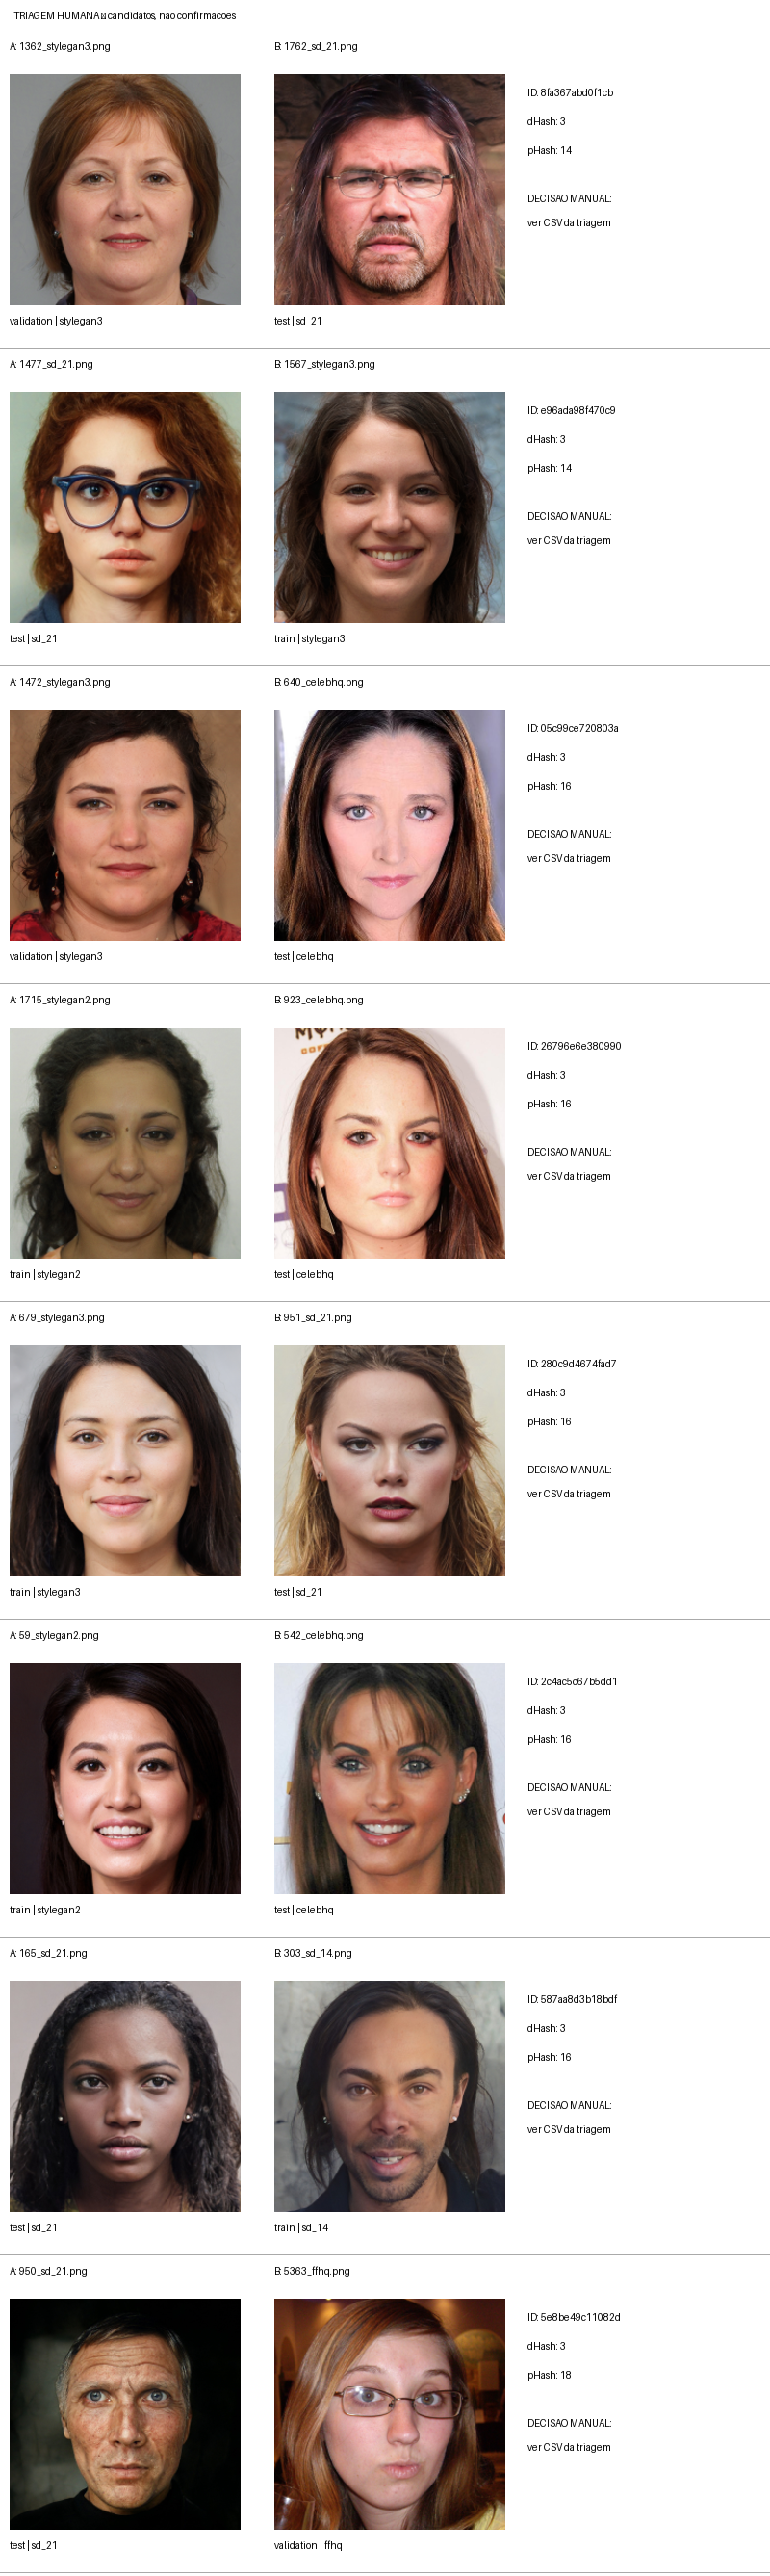

Grupos conectados (NÃO são identidades): 164
Grupos com relação envolvendo teste: 118
Pares da triagem: 12


,pair_id,path_a,path_b,hamming_distance,phash_distance,split_a,split_b,decisao
19,8fa367abd0f1cb9742db,training/dataset_faces_224_m15_yunet_v1/fake/1...,training/dataset_faces_224_m15_yunet_v1/fake/1...,3,14,validation,test,pendente
20,e96ada98f470c9fce02c,training/dataset_faces_224_m15_yunet_v1/fake/1...,training/dataset_faces_224_m15_yunet_v1/fake/1...,3,14,test,train,pendente
22,05c99ce720803ac47bd5,training/dataset_faces_224_m15_yunet_v1/fake/1...,training/dataset_faces_224_m15_yunet_v1/real/6...,3,16,validation,test,pendente
23,26796e6e380990e69e19,training/dataset_faces_224_m15_yunet_v1/fake/1...,training/dataset_faces_224_m15_yunet_v1/real/9...,3,16,train,test,pendente
24,280c9d4674fad7760f31,training/dataset_faces_224_m15_yunet_v1/fake/6...,training/dataset_faces_224_m15_yunet_v1/fake/9...,3,16,train,test,pendente
25,2c4ac5c67b5dd1024aea,training/dataset_faces_224_m15_yunet_v1/fake/5...,training/dataset_faces_224_m15_yunet_v1/real/5...,3,16,train,test,pendente
26,587aa8d3b18bdfd21688,training/dataset_faces_224_m15_yunet_v1/fake/1...,training/dataset_faces_224_m15_yunet_v1/fake/3...,3,16,test,train,pendente
40,5e8be49c11082d66d9ed,training/dataset_faces_224_m15_yunet_v1/fake/9...,training/dataset_faces_224_m15_yunet_v1/real/5...,3,18,test,validation,pendente
53,2b2945856af7f95cba9e,training/dataset_faces_224_m15_yunet_v1/fake/5...,training/dataset_faces_224_m15_yunet_v1/real/1...,3,20,train,test,pendente
60,baedb464246d21983724,training/dataset_faces_224_m15_yunet_v1/fake/4...,training/dataset_faces_224_m15_yunet_v1/real/1...,3,20,test,train,pendente


In [3]:
# 1.2 — Reutilizar pares históricos e criar uma triagem humana pequena.
RH_QUANTIDADE_TRIAGEM = 12
historico = rh_ler_principal()

def rh_grupos_conectados(tabela: pd.DataFrame):
    parent = {}
    def find(x):
        parent.setdefault(x, x)
        while parent[x] != x:
            parent[x] = parent[parent[x]]
            x = parent[x]
        return x
    def union(a, b):
        a, b = find(a), find(b)
        if a != b:
            parent[b] = a

    for par in tabela.itertuples(index=False):
        union(par.path_a, par.path_b)
    nos = defaultdict(set)
    for par in tabela.itertuples(index=False):
        r = find(par.path_a)
        nos[r].update([par.path_a, par.path_b])
    chave = {
        r: hashlib.sha256(min(p).encode('utf-8')).hexdigest()[:12]
        for r, p in nos.items()
    }
    saida = tabela.copy()
    saida['grupo_id'] = saida.path_a.map(lambda x: chave[find(x)])
    saida['envolve_teste'] = saida[['split_a', 'split_b']].eq('test').any(axis=1)
    resumo = saida.groupby('grupo_id', as_index=False).agg(
        pares=('pair_id', 'size'),
        envolve_teste=('envolve_teste', 'any'),
    )
    tamanhos = {chave[r]: len(itens) for r, itens in nos.items()}
    resumo['imagens_unicas'] = resumo.grupo_id.map(tamanhos)
    return saida, resumo


RH_RELACOES, RH_RESUMO_GRUPOS = rh_grupos_conectados(historico)
RH_RESUMO_GRUPOS.sort_values(
    ['pares', 'grupo_id'], ascending=[False, True]
).to_csv(RH_GRUPOS, index=False)

if RH_TRIAGEM.is_file():
    RH_ESCOLHIDOS = pd.read_csv(RH_TRIAGEM, dtype=str, keep_default_na=False)
    if not RH_ESCOLHIDOS.pair_id.is_unique:
        raise ValueError('A triagem histórica contém pair_id repetidos.')
    if not set(RH_ESCOLHIDOS.pair_id).issubset(set(historico.pair_id)):
        raise ValueError('A triagem salva não corresponde ao CSV histórico.')
    print('Triagem já existente preservada:', RH_TRIAGEM)
else:
    elegiveis = RH_RELACOES.loc[
        pd.to_numeric(RH_RELACOES.hamming_distance).eq(3)
        & RH_RELACOES.envolve_teste
    ].copy()
    elegiveis['phash_ordenacao'] = pd.to_numeric(elegiveis.phash_distance)
    elegiveis = elegiveis.sort_values(['phash_ordenacao', 'pair_id'])
    # Um representante por grupo, depois completar pelos menores pHash.
    por_grupo = elegiveis.drop_duplicates('grupo_id').head(RH_QUANTIDADE_TRIAGEM)
    restantes = elegiveis.loc[~elegiveis.pair_id.isin(por_grupo.pair_id)]
    escolhido = pd.concat([
        por_grupo, restantes.head(max(0, RH_QUANTIDADE_TRIAGEM - len(por_grupo)))
    ]).sort_values(['phash_ordenacao', 'pair_id']).head(RH_QUANTIDADE_TRIAGEM)
    if len(escolhido) < RH_QUANTIDADE_TRIAGEM:
        print(f'Aviso: há somente {len(escolhido)} pares elegíveis. Nenhum é inventado.')
    RH_ESCOLHIDOS = escolhido.drop(
        columns=['grupo_id', 'envolve_teste', 'phash_ordenacao']
    ).copy()
    RH_ESCOLHIDOS.to_csv(RH_TRIAGEM, index=False)
    print('Nova seleção salva:', RH_TRIAGEM)

# As pranchas dependem somente dos crops locais já preparados.
def rh_localizar_crop(caminho: str) -> Path:
    texto = str(caminho).strip().replace('\\', '/')
    candidato = Path(texto)
    if candidato.is_file():
        return candidato
    if texto.startswith('training/'):
        candidato = RH_PROJETO / texto
        if candidato.is_file():
            return candidato
    marcador = '/training/'
    if marcador in texto:
        candidato = RH_PROJETO / 'training' / texto.split(marcador, 1)[1]
        if candidato.is_file():
            return candidato
    categoria = Path(texto).parent.name
    return RH_PROJETO / 'training' / 'dataset_faces_224_m15_yunet_v1' / categoria / Path(texto).name


def rh_criar_prancha(lote: pd.DataFrame, destino: Path):
    largura, altura_linha, altura_foto = 800, 330, 240
    tela = Image.new('RGB', (largura, 35 + len(lote) * altura_linha), 'white')
    desenho = ImageDraw.Draw(tela)
    desenho.text((14, 10), 'TRIAGEM HUMANA — candidatos, nao confirmacoes', fill='black')
    for numero, par in enumerate(lote.itertuples(index=False)):
        y = 35 + numero * altura_linha
        for lado, x in [('a', 10), ('b', 285)]:
            arquivo = rh_localizar_crop(getattr(par, f'path_{lado}'))
            with Image.open(arquivo) as img:
                mini = ImageOps.contain(ImageOps.exif_transpose(img).convert('RGB'),
                                       (240, altura_foto))
                tela.paste(mini, (x + (240-mini.width)//2,
                                  y + 42 + (altura_foto-mini.height)//2))
            desenho.text((x, y+7), f'{lado.upper()}: {arquivo.name[:34]}', fill='black')
            desenho.text((x, y+292),
                         f'{getattr(par, "split_"+lado)} | {getattr(par, "source_"+lado)}',
                         fill='black')
        desenho.text((548, y+55), f'ID: {par.pair_id[:14]}', fill='black')
        desenho.text((548, y+85), f'dHash: {par.hamming_distance}', fill='black')
        desenho.text((548, y+115), f'pHash: {par.phash_distance}', fill='black')
        desenho.text((548, y+165), 'DECISAO MANUAL:', fill='black')
        desenho.text((548, y+190), 'ver CSV da triagem', fill='black')
        desenho.line([(0, y+altura_linha-4), (largura, y+altura_linha-4)], fill='#aaaaaa')
    tela.save(destino)


faltantes = [
    str(arquivo) for par in RH_ESCOLHIDOS.itertuples(index=False)
    for arquivo in [rh_localizar_crop(par.path_a), rh_localizar_crop(par.path_b)]
    if not arquivo.is_file()
]
if faltantes:
    print('Não foi possível gerar pranchas: faltam crops locais (primeiros exemplos):')
    for caminho in faltantes[:5]:
        print(' -', caminho)
    print('A triagem CSV foi preservada; copie os crops para gerar as imagens.')
else:
    for inicio in range(0, len(RH_ESCOLHIDOS), 8):
        arquivo = RH_PRANCHAS / f'triagem_complementar_12_{inicio//8+1:03d}.png'
        if not arquivo.is_file():
            rh_criar_prancha(RH_ESCOLHIDOS.iloc[inicio:inicio+8], arquivo)
        print('Prancha:', arquivo)
    if len(RH_ESCOLHIDOS):
        display(Image.open(RH_PRANCHAS / 'triagem_complementar_12_001.png'))

print('Grupos conectados (NÃO são identidades):', len(RH_RESUMO_GRUPOS))
print('Grupos com relação envolvendo teste:', int(RH_RESUMO_GRUPOS.envolve_teste.sum()))
print('Pares da triagem:', len(RH_ESCOLHIDOS))
display(RH_ESCOLHIDOS[['pair_id','path_a','path_b','hamming_distance',
                       'phash_distance','split_a','split_b','decisao']])

In [3]:
# Registrar os 12 pares complementares revisados

curta = pd.read_csv(
    RH_TRIAGEM, dtype=str, keep_default_na=False
)

assert len(curta) == 12, "Quantidade inesperada de pares"
assert curta["decisao"].isin(
    ["pendente", "imagens_distintas"]
).all(), "Existem decisões conflitantes"

pendentes = curta["decisao"].eq("pendente")

curta.loc[pendentes, "decisao"] = "imagens_distintas"
curta.loc[pendentes, "observacao"] = (
    "Revisão visual realizada: não foram observadas "
    "duplicatas evidentes. Identidade não certificada "
    "por metadados."
)
curta.loc[pendentes, "revisor"] = "Guilherme Mathias Reis"
curta.loc[pendentes, "data_revisao"] = "2026-10-19"

curta.to_csv(RH_TRIAGEM, index=False)

print("Pares complementares registrados:", pendentes.sum())


Pares complementares registrados: 12


### 1.3. Incorporar as decisões reais dos 12 pares complementares

**Antes desta célula:** examine as imagens nas pranchas `triagem_complementar_12_001.png` e `...002.png`. Abra `triagem_complementar_12.csv` e edite somente `decisao`, `observacao`, `revisor` e `data_revisao` para os pares de fato examinados. As decisões válidas são `imagens_distintas`, `mesma_imagem`, `mesma_pessoa_imagens_diferentes` e `inconclusivo`. Deixe `pendente` quando não revisar. Salve e feche o arquivo antes de executar.

Esta célula **não classifica imagens automaticamente**. Ela só incorpora decisões manuais, não substitui conflitos e mantém uma cópia de segurança do CSV anterior.

In [4]:
# 1.3 — Importar decisões humanas do CSV curto, sem sobrescrever as demais.
if not RH_TRIAGEM.is_file():
    raise FileNotFoundError(f'Execute a seção 9.2 antes: {RH_TRIAGEM}')

curta = pd.read_csv(RH_TRIAGEM, dtype=str, keep_default_na=False)
principal = rh_ler_principal()
if curta.pair_id.duplicated().any():
    raise ValueError('Há pair_id duplicado no CSV da triagem.')
if not set(curta.pair_id).issubset(set(principal.pair_id)):
    raise ValueError('O CSV complementar tem IDs fora da auditoria histórica.')
if not set(curta.decisao).issubset(RH_DECISOES):
    raise ValueError('Decisões inválidas no CSV complementar.')

por_id = principal.set_index('pair_id')
alteracoes = 0
for _, registro in curta.iterrows():
    if registro['decisao'] == 'pendente':
        continue
    for coluna in ['observacao', 'revisor', 'data_revisao']:
        if not registro[coluna].strip():
            raise ValueError(f'{registro.pair_id}: preencha {coluna} antes de importar.')
    try:
        date.fromisoformat(registro['data_revisao'].strip())
    except ValueError as exc:
        raise ValueError(f'{registro.pair_id}: data deve estar em AAAA-MM-DD.') from exc
    antiga = por_id.at[registro.pair_id, 'decisao']
    if antiga not in ('pendente', registro['decisao']):
        raise ValueError(f'Decisão conflitante para {registro.pair_id}: {antiga}.')
    if antiga == 'pendente':
        for coluna in RH_HUMANAS:
            por_id.at[registro.pair_id, coluna] = registro[coluna]
        alteracoes += 1

if alteracoes:
    destino = rh_salvar_seguro(por_id.reset_index(), RH_PRINCIPAL)
    print('Novas decisões incorporadas:', alteracoes, '| backup:', destino)
else:
    print('Nenhuma nova decisão para incorporar; o histórico foi preservado.')
print('Revisões totais registradas:',
      int(rh_ler_principal().decisao.ne('pendente').sum()))

Novas decisões incorporadas: 12 | backup: /home/guilhermemathiasreis/Documents/synthetic-face-detection/training/analysis/auditoria_duplicatas/backups_revisao_humana/revisao_pares_entre_particoes_20261019_155732_927698.csv
Revisões totais registradas: 30


### 1.4. Emitir relatório complementar da revisão humana

Gera `relatorio_triagem_humana.md` e `relatorio_triagem_humana.json` **a partir do CSV já atualizado**, sem mexer no relatório da auditoria anterior. As contagens representam somente decisões realmente gravadas e documentam as limitações da triagem.


In [5]:
# 1.4 — Relatório reproduzível a partir do histórico + decisões humanas.
final = rh_ler_principal()
distancia = pd.to_numeric(final.hamming_distance)
teste = final[['split_a', 'split_b']].eq('test').any(axis=1)
revisados = final.decisao.ne('pendente')
prioritarios = distancia.le(2)
confirmados_imagem = final.decisao.eq('mesma_imagem')
confirmados_pessoa = final.decisao.eq('mesma_pessoa_imagens_diferentes')
inconclusivos = final.decisao.eq('inconclusivo')

if RH_HISTORICO_JSON.is_file():
    registro_anterior = json.loads(RH_HISTORICO_JSON.read_text(encoding='utf-8'))
else:
    registro_anterior = {}

resumo = {
    'gerado_em_utc': datetime.now(timezone.utc).isoformat(),
    'origem': str(RH_PRINCIPAL.relative_to(RH_PROJETO)),
    'escopo': 'revisão humana dirigida sobre pares já encontrados por dHash',
    'imagens_originais': registro_anterior.get('imagens_originais'),
    'crops_validos': registro_anterior.get('crops_validos'),
    'pares_candidatos_total': registro_anterior.get('pares_candidatos_total'),
    'pares_entre_particoes': int(len(final)),
    'pares_entre_particoes_envolvendo_teste': int(teste.sum()),
    'prioritarios_dhash_0_2': int(prioritarios.sum()),
    'prioritarios_revisados': int((prioritarios & revisados).sum()),
    'complementares_selecionados': int(len(pd.read_csv(RH_TRIAGEM))) if RH_TRIAGEM.is_file() else 0,
    'complementares_revisados': 0,
    'total_revisados': int(revisados.sum()),
    'total_pendentes': int((~revisados).sum()),
    'revisados_envolvendo_teste': int((revisados & teste).sum()),
    'imagens_distintas_por_revisao': int(final.decisao.eq('imagens_distintas').sum()),
    'mesma_imagem_confirmada': int(confirmados_imagem.sum()),
    'mesma_pessoa_confirmada': int(confirmados_pessoa.sum()),
    'inconclusivos': int(inconclusivos.sum()),
    'grupos_conectados': None,
    'grupos_com_pares_envolvendo_teste': None,
    'criterio': 'dHash 0–2; triagem adicional dHash 3 envolvendo teste, com pHash e grupos conectados',
    'limite': 'somente pares inspecionados; não certifica independência visual ou de identidade integral'
}

if RH_TRIAGEM.is_file():
    ids_adicionais = set(pd.read_csv(RH_TRIAGEM, dtype=str).pair_id)
    resumo['complementares_revisados'] = int((revisados & final.pair_id.isin(ids_adicionais)).sum())
if RH_GRUPOS.is_file():
    tabelagrupos = pd.read_csv(RH_GRUPOS)
    resumo['grupos_conectados'] = int(len(tabelagrupos))
    resumo['grupos_com_pares_envolvendo_teste'] = int(tabelagrupos.envolve_teste.sum())

RH_RELATORIO_JSON.write_text(json.dumps(resumo, ensure_ascii=False, indent=2), encoding='utf-8')

def rh_numero(valor):
    return 'não informado no histórico' if valor is None else f'{valor:,}'.replace(',', '.')

texto = f"""# Complemento — revisão humana direcionada da auditoria perceptual

**Base:** `training/analysis/auditoria_duplicatas/revisao_pares_entre_particoes.csv` e relatórios de auditoria já existentes.  
**Gerado em (UTC):** {resumo['gerado_em_utc']}.

## Histórico preservado

- Imagens originais: **{rh_numero(resumo['imagens_originais'])}**; crops válidos: **{rh_numero(resumo['crops_validos'])}**.
- Candidatos dHash totais no relatório anterior: **{rh_numero(resumo['pares_candidatos_total'])}**.
- Candidatos entre partições existentes no CSV: **{rh_numero(len(final))}**, dos quais **{rh_numero(int(teste.sum()))}** envolvem teste.
- Pares com dHash de 0 a 2: **{rh_numero(int(prioritarios.sum()))}**.

## Procedimento e cobertura humana

- Prioritários dHash 0–2 com decisão registrada: **{rh_numero(resumo['prioritarios_revisados'])}/{rh_numero(resumo['prioritarios_dhash_0_2'])}**.
- Complementares selecionados: **{rh_numero(resumo['complementares_selecionados'])}**, dos quais **{rh_numero(resumo['complementares_revisados'])}** com decisão registrada.
- Total entre partições com decisão: **{rh_numero(resumo['total_revisados'])}/{rh_numero(resumo['pares_entre_particoes'])}**.
- Pares revisados envolvendo teste: **{rh_numero(resumo['revisados_envolvendo_teste'])}**.
- Pares pendentes de revisão: **{rh_numero(resumo['total_pendentes'])}**.
- Classificados como imagens distintas: **{rh_numero(resumo['imagens_distintas_por_revisao'])}**.
- Confirmados como mesma imagem: **{rh_numero(resumo['mesma_imagem_confirmada'])}**.
- Marcados como mesma pessoa em imagens diferentes: **{rh_numero(resumo['mesma_pessoa_confirmada'])}**.
- Inconclusivos: **{rh_numero(resumo['inconclusivos'])}**.
- Grupos conectados por pares candidatos: **{rh_numero(resumo['grupos_conectados'])}** (não equivalem a identidades).
- Grupos com ao menos uma relação envolvendo teste: **{rh_numero(resumo['grupos_com_pares_envolvendo_teste'])}**.

**Critério:** priorizar pares dHash 0–2; complementar com candidatos de dHash 3 envolvendo o teste, menor pHash e diversidade de grupos conectados. As classificações são humanas, registradas por par, revisor e data no CSV.

## Interpretação e limites

A revisão documenta somente as relações efetivamente inspecionadas; pares ainda pendentes não são considerados duplicatas nem descartados como semelhantes. As distâncias dHash/pHash não provam identidade. Um grupo conectado por pares candidatos não significa que suas imagens sejam da mesma pessoa. Não se demonstra ausência completa de sobreposição visual ou de identidade entre partições. O conjunto de teste e os checkpoints não foram alterados por estas etapas.

**Encaminhamento:** se houver par confirmado envolvendo teste ou situação inconclusiva relevante, avaliar o impacto e discuti-lo com o orientador; não alterar silenciosamente o protocolo nem os resultados originais.

**Evidências:** `revisao_pares_entre_particoes.csv`, `triagem_complementar_12.csv` (quando existir), `agrupamentos_candidatos_revisao.csv`, pranchas de comparação e o histórico `relatorio_auditoria_duplicatas.json`.
"""
RH_RELATORIO.write_text(texto, encoding='utf-8')

print(texto)
print('Relatório suplementar:', RH_RELATORIO)
print('Resumo JSON:', RH_RELATORIO_JSON)

# Complemento — revisão humana direcionada da auditoria perceptual

**Base:** `training/analysis/auditoria_duplicatas/revisao_pares_entre_particoes.csv` e relatórios de auditoria já existentes.  
**Gerado em (UTC):** 2026-10-19T18:57:34.716789+00:00.

## Histórico preservado

- Imagens originais: **16.000**; crops válidos: **15.960**.
- Candidatos dHash totais no relatório anterior: **2.374**.
- Candidatos entre partições existentes no CSV: **1.224**, dos quais **988** envolvem teste.
- Pares com dHash de 0 a 2: **18**.

## Procedimento e cobertura humana

- Prioritários dHash 0–2 com decisão registrada: **18/18**.
- Complementares selecionados: **12**, dos quais **12** com decisão registrada.
- Total entre partições com decisão: **30/1.224**.
- Pares revisados envolvendo teste: **27**.
- Pares pendentes de revisão: **1.194**.
- Classificados como imagens distintas: **30**.
- Confirmados como mesma imagem: **0**.
- Marcados como mesma pessoa em imagens diferentes: **0**.
- Inconclusivo